In [37]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor, plot_importance
from sklearn.dummy import DummyRegressor


In [22]:
data = pd.read_csv(r"..\ml_dataset.csv")

In [23]:
data["delivery_day"] = pd.to_datetime(data["delivery_day"])
data = data.sort_values(["delivery_day", "hour"]).reset_index(drop=True)

In [66]:
data = data[data["delivery_day"] >= "2026-04-01"]

In [67]:
data.head(-5)

,delivery_day,hour,price_value,buy_volume_value,sell_volume_value,net_volume,flow_DK1_export,flow_DK1_import,flow_GER_export,flow_GER_import,...,no1_reservoir_level_MWh,no5_reservoir_level_MWh,flow_DK1_export_lag24,flow_DK1_export_lag48,flow_DK1_export_lag168,flow_DK1_import_lag24,flow_DK1_import_lag48,flow_DK1_import_lag168,target_1h,target_24h
13126,2026-04-01,0,117.2675,20628.2,26337.5,-5709.3,218.5,0.0,450.0,0.0,...,1017674.0,3589179.0,0.0,0.0,0.0,718.6,1680.0,1680.0,484.4,1631.3
13127,2026-04-01,1,117.8500,19723.9,26554.8,-6830.9,484.4,0.0,1444.0,0.0,...,1017674.0,3589179.0,0.0,0.0,0.0,1217.9,1680.0,1680.0,451.6,1631.3
13128,2026-04-01,2,117.0225,19424.5,25040.3,-5615.8,451.6,0.0,1444.0,0.0,...,1017674.0,3589179.0,0.0,0.0,0.0,1286.8,1680.0,1680.0,510.6,1631.3
13129,2026-04-01,3,115.8025,18674.1,23742.1,-5068.0,510.6,0.0,1444.0,0.0,...,1017674.0,3589179.0,0.0,0.0,0.0,1096.4,1680.0,1680.0,783.5,1253.0
13130,2026-04-01,4,115.4700,17263.0,23855.5,-6592.5,783.5,0.0,1444.0,0.0,...,1017674.0,3589179.0,0.0,0.0,0.0,1343.0,1680.0,1680.0,1141.8,990.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16954,2026-09-07,12,133.9850,15131.4,12394.8,2736.6,0.0,0.0,0.0,1399.2,...,4353693.0,11287245.0,0.0,0.0,0.0,942.0,0.0,1428.0,0.0,0.0
16955,2026-09-07,13,131.5775,14533.5,11943.4,2590.1,0.0,0.0,0.0,1330.4,...,4353693.0,11287245.0,0.0,115.1,0.0,942.0,0.0,1428.0,0.0,0.0
16956,2026-09-07,14,130.0825,14313.2,12453.9,1859.3,0.0,0.0,0.0,1379.4,...,4353693.0,11287245.0,0.0,86.3,0.0,942.0,112.9,1428.0,0.0,0.0
16957,2026-09-07,15,132.4850,14528.8,11075.1,3453.7,0.0,0.0,0.0,1306.8,...,4353693.0,11287245.0,0.0,0.0,0.0,942.0,562.9,1428.0,0.0,0.0


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 17014 entries, 0 to 17013
Data columns (total 67 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   delivery_day             17014 non-null  datetime64[us]
 1   hour                     17014 non-null  int64         
 2   price_value              17014 non-null  float64       
 3   buy_volume_value         17014 non-null  float64       
 4   sell_volume_value        17014 non-null  float64       
 5   net_volume               17014 non-null  float64       
 6   flow_DK1_export          17014 non-null  float64       
 7   flow_DK1_import          17014 non-null  float64       
 8   flow_GER_export          17014 non-null  float64       
 9   flow_GER_import          17014 non-null  float64       
 10  flow_NL_export           17014 non-null  float64       
 11  flow_NL_import           17014 non-null  float64       
 12  flow_NO1_export          17014 non-null  fl

In [25]:
data = data.drop(columns = ["capacity_GER", 
                  "capacity_NL", 
                  "capacity_NO1",
                  "capacity_NO5", 
                  'capacity_missing_DK1',
                  'capacity_missing_GER',
                  'capacity_missing_NL',
                  'capacity_missing_NO1',
                  'capacity_missing_NO5',
                  'capacity_zero_DK1',
                  'capacity_zero_GER',
                  'capacity_zero_NL',
                  'capacity_zero_NO1',
                  'capacity_zero_NO5', 
                  'util_GER',
                  'util_NL',
                  'util_NO1',
                  'util_NO5',
                 ])

In [68]:
data["target_1h"] = data["flow_DK1_export"].shift(-1)
data["target_24h"] = data["flow_DK1_export"].shift(-24)

data = data.dropna(subset=["target_1h", "target_24h"]) 

In [69]:
feature = "flow_DK1_export"
relevant_feature = "flow_DK1_import"

data[feature + "_lag24"] = data[feature].shift(24)
data[feature + "_lag48"] = data[feature].shift(48)
data[feature + "_lag168"] = data[feature].shift(168)
data[relevant_feature + "_lag24"] = data[relevant_feature].shift(24)
data[relevant_feature + "_lag48"] = data[relevant_feature].shift(48)
data[relevant_feature + "_lag168"] = data[relevant_feature].shift(168)

In [70]:
for i in range(len(data.columns.tolist())):
    if data.columns.tolist()[i] == "target_1h":
        continue
    if data.columns.tolist()[i] == "target_24h":
        continue
    if data.columns.tolist()[i] == "delivery_day":
        continue
    print("'" + data.columns.tolist()[i] + "',")

'hour',
'price_value',
'buy_volume_value',
'sell_volume_value',
'net_volume',
'flow_DK1_export',
'flow_DK1_import',
'flow_GER_export',
'flow_GER_import',
'flow_NL_export',
'flow_NL_import',
'flow_NO1_export',
'flow_NO1_import',
'flow_NO5_export',
'flow_NO5_import',
'price_DK1',
'price_NO1',
'price_NO5',
'total_exports',
'total_imports',
'net_flow',
'day_of_week',
'month',
'day_of_year',
'day_sin',
'day_cos',
'year_sin',
'year_cos',
'price_lag_24',
'price_lag_168',
'price_DK1_lag24',
'price_NO1_lag24',
'price_NO5_lag24',
'price_DK1_lag168',
'price_NO1_lag168',
'price_NO5_lag168',
'price_NL',
'price_DE_LU',
'price_BE',
'price_FR',
'Solar',
'Wind Onshore',
'Wind Offshore',
'Forecasted Generation',
'Forecasted Load',
'no2_reservoir_level_MWh',
'no1_reservoir_level_MWh',
'no5_reservoir_level_MWh',
'flow_DK1_export_lag24',
'flow_DK1_export_lag48',
'flow_DK1_export_lag168',
'flow_DK1_import_lag24',
'flow_DK1_import_lag48',
'flow_DK1_import_lag168',


In [71]:
feature_columns = [
'hour',
'price_value',
'buy_volume_value',
'sell_volume_value',
'net_volume',
'flow_DK1_export',
'flow_DK1_import',
'flow_GER_export',
'flow_GER_import',
'flow_NL_export',
'flow_NL_import',
'flow_NO1_export',
'flow_NO1_import',
'flow_NO5_export',
'flow_NO5_import',
'price_DK1',
'price_NO1',
'price_NO5',
'total_exports',
'total_imports',
'net_flow',
'day_of_week',
'month',
'day_of_year',
'day_sin',
'day_cos',
'year_sin',
'year_cos',
'price_lag_24',
'price_lag_168',
'price_DK1_lag24',
'price_NO1_lag24',
'price_NO5_lag24',
'price_DK1_lag168',
'price_NO1_lag168',
'price_NO5_lag168',
'price_NL',
'price_DE_LU',
'price_BE',
'price_FR',
'Solar',
'Wind Onshore',
'Wind Offshore',
'Forecasted Generation',
'Forecasted Load',
'no2_reservoir_level_MWh',
'no1_reservoir_level_MWh',
'no5_reservoir_level_MWh',
'flow_DK1_export_lag24',
'flow_DK1_export_lag48',
'flow_DK1_export_lag168',
'flow_DK1_import_lag24',
'flow_DK1_import_lag48',
'flow_DK1_import_lag168'
]

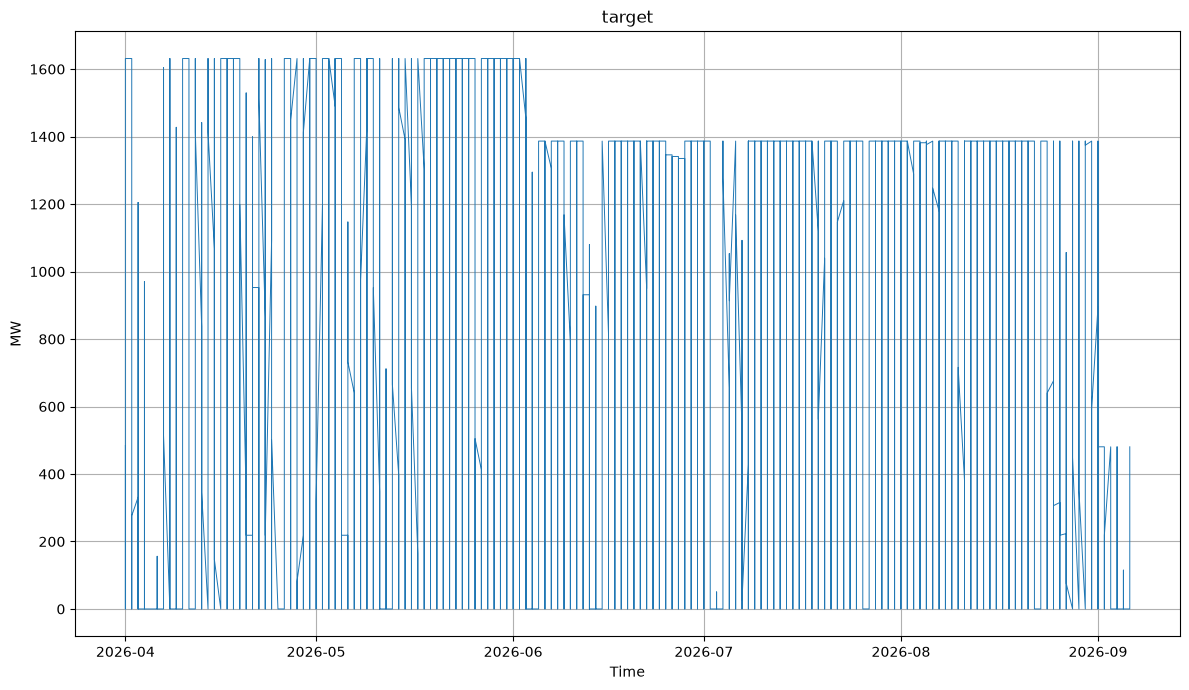

In [94]:
plt.figure(figsize=(12, 7))
plt.plot(data["delivery_day"], data["target_1h"], linewidth=0.7)
plt.xlabel("Time")
plt.ylabel("MW")
plt.title("target")
plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
def evaluate(y_true, y_pred):
    return {
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
    }

In [15]:
def plot_results(x_data, test_pred, test_targets, test_pred_label, test_target_label, title, y_label):  
    plt.figure(figsize=(12, 7))
    plt.plot(x_data, test_pred, label=test_pred_label, linewidth=0.7)
    plt.plot(x_data, test_targets, label=test_target_label, linewidth=0.7)
    plt.xlabel("Time")
    plt.ylabel(y_label)
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [75]:
feature_data_1h = data[feature_columns]
target_data_1h = data['target_1h']

Dummy regressor scores:
  MSE: 373525.2509
  RMSE: 611.1671
  R2: -0.0170
  MAE: 579.9382


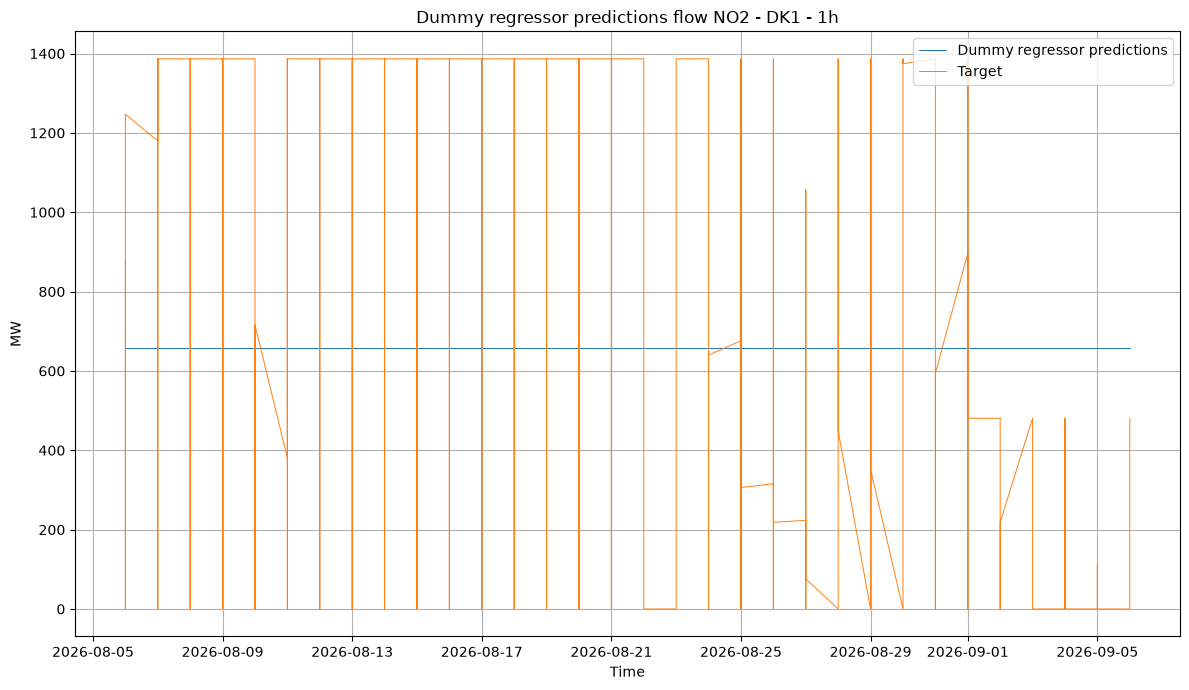

In [77]:
train_end = int(len(feature_data_1h) * 0.8)

train_data = feature_data_1h.iloc[:train_end]
train_targets = target_data_1h.iloc[:train_end]

test_data = feature_data_1h.iloc[train_end:]
test_targets = target_data_1h.iloc[train_end:]

dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(train_data, train_targets)

dummy_test_pred = dummy_model.predict(test_data)

dummy_test_scores_1h = evaluate(test_targets, dummy_test_pred)

print("Dummy regressor scores:")
for name, score in dummy_test_scores_1h.items():
    print(f"  {name}: {score:.4f}")


x_data = data.loc[test_data.index, "delivery_day"]
plot_results(x_data=x_data, 
             test_pred=dummy_test_pred, 
             test_targets=test_targets, 
             test_pred_label="Dummy regressor predictions", 
             test_target_label="Target", 
             title="Dummy regressor predictions flow NO2 - DK1 - 1h", 
             y_label="MW")

In [78]:
train_end = int(len(feature_data_1h) * 0.7)
val_end = int(len(feature_data_1h) * 0.85)

train_data = feature_data_1h.iloc[:train_end]
train_targets = target_data_1h.iloc[:train_end]

validation_data = feature_data_1h.iloc[train_end:val_end]
validation_targets = target_data_1h.iloc[train_end:val_end]

test_data = feature_data_1h.iloc[val_end:]
test_targets = target_data_1h.iloc[val_end:]


xgb_model = XGBRegressor(
    objective='reg:squarederror',
    eval_metric="rmse",
    min_child_weight=3,
    n_estimators=2000,
    max_depth=5,
    learning_rate=0.035,
    subsample=0.9,
    colsample_bytree=0.95,
    #gamma=0.05,
    reg_lambda=5.0,
    reg_alpha=0.0,
    random_state=42,
    n_jobs=-1,
    verbosity=0,
    early_stopping_rounds=200
)

xgb_model.fit(
    train_data,
    train_targets,
    eval_set=[(validation_data, validation_targets)],
    verbose=True,
)

xgb_val_pred = xgb_model.predict(validation_data)
xgb_test_pred = xgb_model.predict(test_data)

xgb_val_scores_1h = evaluate(validation_targets, xgb_val_pred)
xgb_test_scores_1h = evaluate(test_targets, xgb_test_pred)

print("XGBoost regressor validation scores:")
for name, score in xgb_val_scores_1h.items():
    print(f"  {name}: {score:.4f}")

print("XGBoost regressor test scores:")
for name, score in xgb_test_scores_1h.items():
    print(f"  {name}: {score:.4f}")

[0]	validation_0-rmse:623.03098
[1]	validation_0-rmse:605.27885
[2]	validation_0-rmse:587.75974
[3]	validation_0-rmse:572.37476
[4]	validation_0-rmse:554.98990
[5]	validation_0-rmse:539.12421
[6]	validation_0-rmse:524.00171
[7]	validation_0-rmse:508.38118
[8]	validation_0-rmse:493.84374
[9]	validation_0-rmse:481.04255
[10]	validation_0-rmse:467.39930
[11]	validation_0-rmse:453.27037
[12]	validation_0-rmse:439.89939
[13]	validation_0-rmse:428.87544
[14]	validation_0-rmse:416.86511
[15]	validation_0-rmse:405.19890
[16]	validation_0-rmse:394.08513
[17]	validation_0-rmse:382.82178
[18]	validation_0-rmse:373.83547
[19]	validation_0-rmse:364.35392
[20]	validation_0-rmse:356.53360
[21]	validation_0-rmse:347.26406
[22]	validation_0-rmse:340.12629
[23]	validation_0-rmse:333.72585
[24]	validation_0-rmse:325.48515
[25]	validation_0-rmse:319.45536
[26]	validation_0-rmse:312.50263
[27]	validation_0-rmse:305.33829
[28]	validation_0-rmse:299.75617
[29]	validation_0-rmse:294.13690
[30]	validation_0-rm

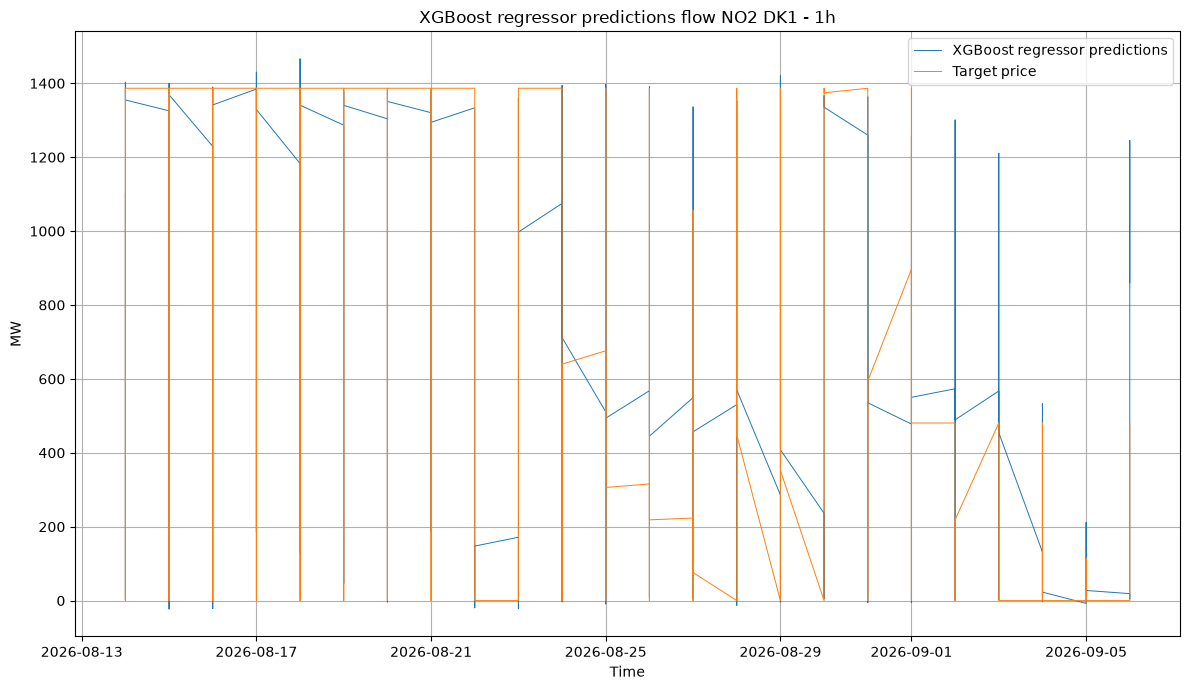

In [79]:
x_data = data.loc[test_data.index, "delivery_day"]
plot_results(x_data=x_data, 
             test_pred=xgb_test_pred, 
             test_targets=test_targets, 
             test_pred_label="XGBoost regressor predictions", 
             test_target_label="Target price", 
             title="XGBoost regressor predictions flow NO2 DK1 - 1h", 
             y_label="MW")

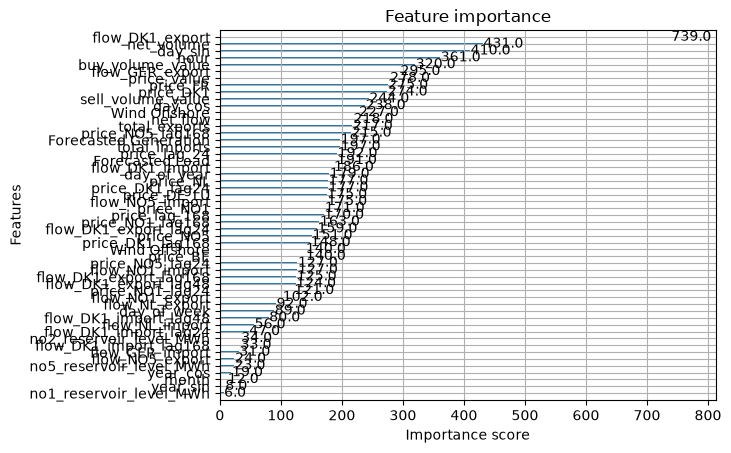

In [80]:
plot_importance(xgb_model)
plt.show()

In [81]:
xgb_model.get_booster().get_score(importance_type='weight')


{'hour': 361.0,
 'price_value': 278.0,
 'buy_volume_value': 320.0,
 'sell_volume_value': 244.0,
 'net_volume': 431.0,
 'flow_DK1_export': 739.0,
 'flow_DK1_import': 186.0,
 'flow_GER_export': 295.0,
 'flow_GER_import': 31.0,
 'flow_NL_export': 92.0,
 'flow_NL_import': 56.0,
 'flow_NO1_export': 102.0,
 'flow_NO1_import': 127.0,
 'flow_NO5_export': 24.0,
 'flow_NO5_import': 175.0,
 'price_DK1': 274.0,
 'price_NO1': 171.0,
 'price_NO5': 151.0,
 'total_exports': 217.0,
 'total_imports': 197.0,
 'net_flow': 218.0,
 'day_of_week': 89.0,
 'month': 12.0,
 'day_of_year': 179.0,
 'day_sin': 410.0,
 'day_cos': 238.0,
 'year_sin': 8.0,
 'year_cos': 19.0,
 'price_lag_24': 192.0,
 'price_lag_168': 170.0,
 'price_DK1_lag24': 177.0,
 'price_NO1_lag24': 121.0,
 'price_NO5_lag24': 127.0,
 'price_DK1_lag168': 148.0,
 'price_NO1_lag168': 163.0,
 'price_NO5_lag168': 215.0,
 'price_NL': 177.0,
 'price_DE_LU': 175.0,
 'price_BE': 140.0,
 'price_FR': 275.0,
 'Wind Onshore': 227.0,
 'Wind Offshore': 140.0,
 'F

In [82]:
feature_data_24h = data[feature_columns]
target_data_24h = data['target_24h']

Dummy regressor scores:
  MSE: 372248.5858
  RMSE: 610.1218
  R2: -0.0172
  MAE: 578.2900


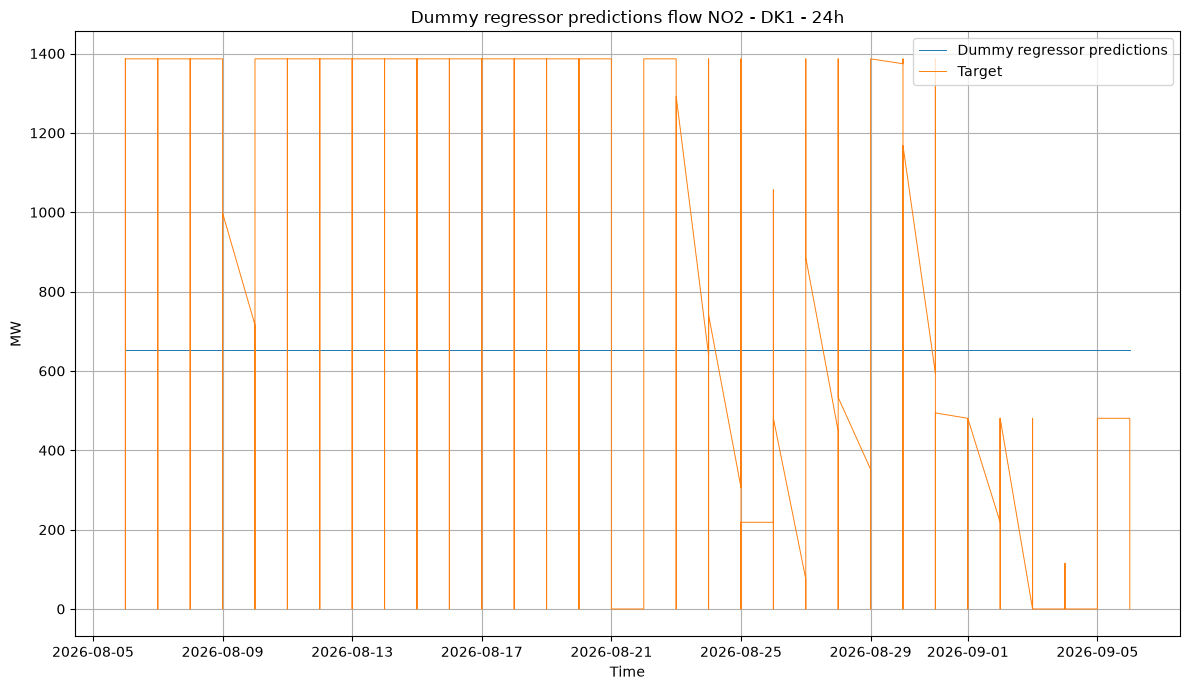

In [83]:
train_end = int(len(feature_data_24h) * 0.8)

train_data = feature_data_24h.iloc[:train_end]
train_targets = target_data_24h.iloc[:train_end]

test_data = feature_data_24h.iloc[train_end:]
test_targets = target_data_24h.iloc[train_end:]

dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(train_data, train_targets)

dummy_test_pred = dummy_model.predict(test_data)

dummy_test_scores_24h = evaluate(test_targets, dummy_test_pred)

print("Dummy regressor scores:")
for name, score in dummy_test_scores_24h.items():
    print(f"  {name}: {score:.4f}")


x_data = data.loc[test_data.index, "delivery_day"]
plot_results(x_data=x_data, 
             test_pred=dummy_test_pred, 
             test_targets=test_targets, 
             test_pred_label="Dummy regressor predictions", 
             test_target_label="Target", 
             title="Dummy regressor predictions flow NO2 - DK1 - 24h", 
             y_label="MW")

In [84]:
train_end = int(len(feature_data_24h) * 0.7)
val_end = int(len(feature_data_24h) * 0.85)

train_data = feature_data_24h.iloc[:train_end]
train_targets = target_data_24h.iloc[:train_end]

validation_data = feature_data_24h.iloc[train_end:val_end]
validation_targets = target_data_24h.iloc[train_end:val_end]

test_data = feature_data_24h.iloc[val_end:]
test_targets = target_data_24h.iloc[val_end:]


xgb_model = XGBRegressor(
    objective='reg:squarederror',
    eval_metric="rmse",
    min_child_weight=3,
    n_estimators=2000,
    max_depth=5,
    learning_rate=0.035,
    subsample=0.9,
    colsample_bytree=0.95,
    #gamma=0.05,
    reg_lambda=5.0,
    reg_alpha=0.0,
    random_state=42,
    n_jobs=-1,
    verbosity=0,
    early_stopping_rounds=200
)

xgb_model.fit(
    train_data,
    train_targets,
    eval_set=[(validation_data, validation_targets)],
    verbose=True,
)

xgb_val_pred = xgb_model.predict(validation_data)
xgb_test_pred = xgb_model.predict(test_data)

xgb_val_scores_24h = evaluate(validation_targets, xgb_val_pred)
xgb_test_scores_24h = evaluate(test_targets, xgb_test_pred)

print("XGBoost regressor validation scores:")
for name, score in xgb_val_scores_24h.items():
    print(f"  {name}: {score:.4f}")

print("XGBoost regressor test scores:")
for name, score in xgb_test_scores_24h.items():
    print(f"  {name}: {score:.4f}")

[0]	validation_0-rmse:625.46580
[1]	validation_0-rmse:612.01587
[2]	validation_0-rmse:597.22245
[3]	validation_0-rmse:583.12792
[4]	validation_0-rmse:569.38458
[5]	validation_0-rmse:555.83816
[6]	validation_0-rmse:545.11207
[7]	validation_0-rmse:533.47452
[8]	validation_0-rmse:522.24982
[9]	validation_0-rmse:513.24357
[10]	validation_0-rmse:504.41322
[11]	validation_0-rmse:494.14566
[12]	validation_0-rmse:486.00129
[13]	validation_0-rmse:476.29621
[14]	validation_0-rmse:468.93450
[15]	validation_0-rmse:460.16279
[16]	validation_0-rmse:452.63597
[17]	validation_0-rmse:446.70118
[18]	validation_0-rmse:438.42715
[19]	validation_0-rmse:431.69094
[20]	validation_0-rmse:424.37066
[21]	validation_0-rmse:419.72491
[22]	validation_0-rmse:413.00230
[23]	validation_0-rmse:408.70960
[24]	validation_0-rmse:403.20679
[25]	validation_0-rmse:399.37552
[26]	validation_0-rmse:395.02821
[27]	validation_0-rmse:390.99658
[28]	validation_0-rmse:388.45538
[29]	validation_0-rmse:384.56959
[30]	validation_0-rm

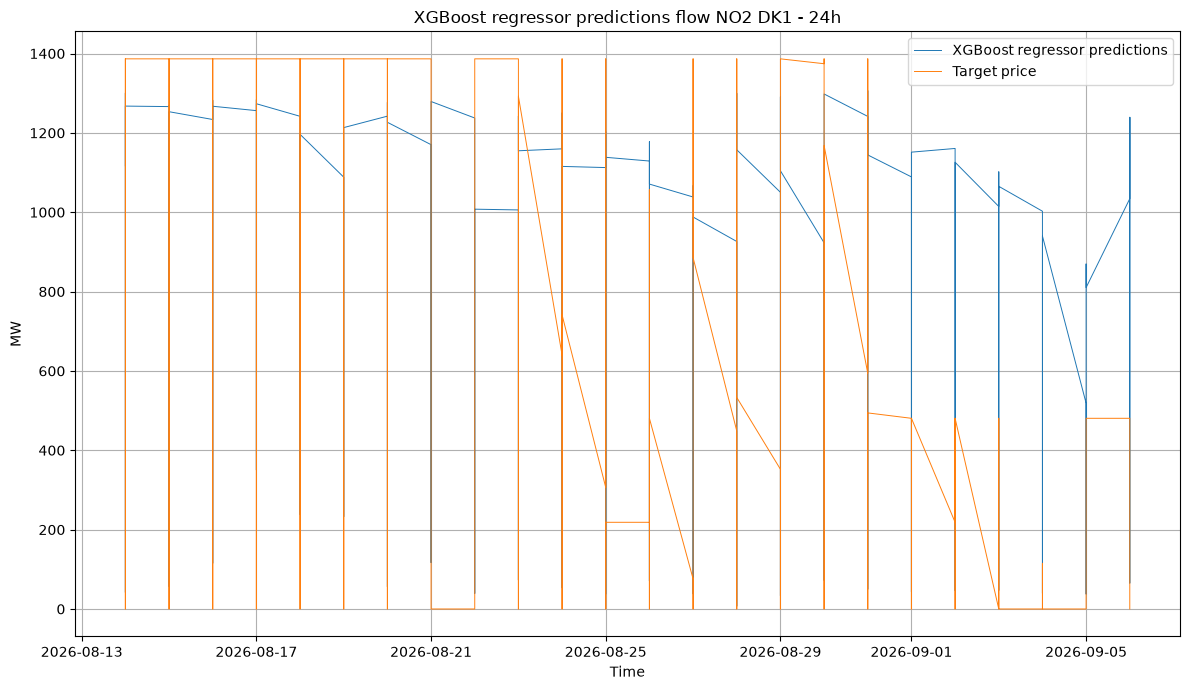

In [85]:
x_data = data.loc[test_data.index, "delivery_day"]
plot_results(x_data=x_data, 
             test_pred=xgb_test_pred, 
             test_targets=test_targets, 
             test_pred_label="XGBoost regressor predictions", 
             test_target_label="Target price", 
             title="XGBoost regressor predictions flow NO2 DK1 - 24h", 
             y_label="MW")

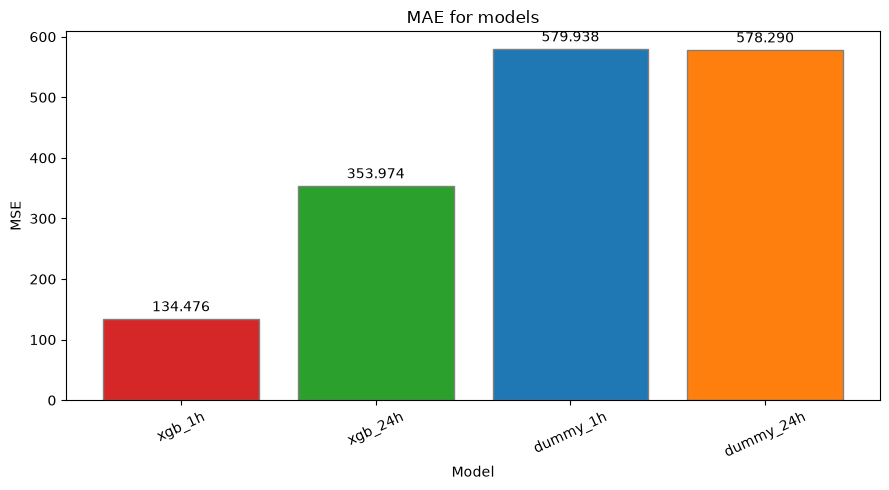

In [92]:
metrics = ["RMSE", "MSE", "R2", "MAE"]
colors = {
    "xgb_1h": "tab:red",
    "xgb_24h": "tab:green",
    "dummy_1h": "tab:blue",
    "dummy_24h": "tab:orange",
}
results = {"xgb_1h" : xgb_test_scores_1h, "xgb_24h" : xgb_test_scores_24h, "dummy_1h" : dummy_test_scores_1h, "dummy_24h" : dummy_test_scores_24h,}
models = list(results.keys())

# MAE
mae_scores = [results[model]["MAE"] for model in models]
mae_colors = [colors[model] for model in models]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(models, mae_scores, color=mae_colors, edgecolor="grey")
ax.set_title("MAE for models")
ax.set_xlabel("Model")
ax.set_ylabel("MSE")
ax.tick_params(axis="x", rotation=25)
ax.bar_label(bars, fmt="%.3f", padding=3)
fig.tight_layout()
plt.show()